## 1. Import Dependencies

In [1]:
%pip install xgboost scikit-learn seaborn


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\nabila\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [ ]:
# !git clone https://github.com/nabila-natasha/hotel-booking-cancellation-ml.git
# %cd hotel-booking-cancellation-ml/notebooks

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Load Cleaned Dataset

In [3]:
df = pd.read_csv('../data/processed/hotels_clean.csv')

In [4]:
df.shape

(84392, 27)

In [5]:
df.head().T

,0,1,2,3,4
hotel,resort_hotel,resort_hotel,resort_hotel,resort_hotel,resort_hotel
is_canceled,0,0,0,0,0
lead_time,7,13,14,0,9
arrival_date_year,2015,2015,2015,2015,2015
arrival_date_month,july,july,july,july,july
arrival_date_week_number,27,27,27,27,27
arrival_date_day_of_month,1,1,1,1,1
stays_in_weekend_nights,0,0,0,0,0
stays_in_week_nights,1,1,2,2,2
adults,1,1,2,2,2


In [6]:
df.dtypes

hotel                              object
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                 object
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                               object
country                            object
market_segment                     object
distribution_channel               object
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                 object
deposit_type                       object
agent                               int64
days_in_waiting_list                int64
customer_type                     

In [7]:
df['is_canceled'].value_counts(normalize=True)

is_canceled
0    0.721016
1    0.278984
Name: proportion, dtype: float64

## 3. Split Training, Validation and Testing Data

In [8]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.feature_extraction import DictVectorizer

In [9]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42, stratify=df['is_canceled']) # stratify to preserve the cancellation proportions across the datasets.

df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42, stratify=df_full_train['is_canceled'])

In [10]:
len(df_train) , len(df_val) , len(df_test) , len(df)

(50634, 16879, 16879, 84392)

In [11]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [12]:
y_train = df_train['is_canceled'].values
y_val = df_val['is_canceled'].values
y_test = df_test['is_canceled'].values

In [13]:
del df_train['is_canceled']
del df_val['is_canceled']
del df_test['is_canceled']

In [14]:
df_train

,hotel,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,...,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,deposit_type,agent,days_in_waiting_list,customer_type,adr,total_of_special_requests,has_company
0,city_hotel,0,2016,january,2,3,1,0,1,0.0,...,0,0,a,no_deposit,9,0,transient,81.00,0,0
1,city_hotel,72,2016,april,17,23,2,2,2,0.0,...,0,0,a,no_deposit,9,0,transient,95.20,1,0
2,city_hotel,0,2017,june,26,26,1,3,2,0.0,...,0,0,a,no_deposit,14,0,transient,112.50,0,0
3,city_hotel,64,2017,july,30,29,0,1,2,0.0,...,0,0,a,no_deposit,9,0,transient,150.00,2,0
4,city_hotel,226,2017,march,10,7,0,2,2,0.0,...,0,0,a,no_deposit,83,0,transient,72.00,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50629,resort_hotel,115,2017,may,18,4,2,3,2,0.0,...,0,0,d,no_deposit,177,0,transient,56.00,0,0
50630,city_hotel,4,2016,august,36,29,1,0,3,0.0,...,0,0,d,no_deposit,9,0,transient,184.00,0,0
50631,resort_hotel,11,2015,august,31,1,4,10,1,0.0,...,0,0,a,no_deposit,104,0,transient,172.00,0,0
50632,city_hotel,298,2016,october,42,9,2,5,2,0.0,...,0,0,d,no_deposit,7,0,transient,79.59,1,0


## 4. Convert DataFrames into Dictionaries

In [15]:
train_dicts = df_train.to_dict(orient="records")

In [16]:
# Create DictVectorizer

dv = DictVectorizer(sparse=False)

In [17]:
# Learn feature names and transform training data

X_train = dv.fit_transform(train_dicts)

In [18]:
X_train

array([[ 81.  ,   1.  ,   9.  , ...,   0.  ,   1.  ,   0.  ],
       [ 95.2 ,   2.  ,   9.  , ...,   2.  ,   2.  ,   1.  ],
       [112.5 ,   2.  ,  14.  , ...,   3.  ,   1.  ,   0.  ],
       ...,
       [172.  ,   1.  , 104.  , ...,  10.  ,   4.  ,   0.  ],
       [ 79.59,   2.  ,   7.  , ...,   5.  ,   2.  ,   1.  ],
       [ 89.1 ,   2.  ,   9.  , ...,   4.  ,   2.  ,   2.  ]],
      shape=(50634, 224))

In [19]:
dv.get_feature_names_out()

array(['adr', 'adults', 'agent', 'arrival_date_day_of_month',
       'arrival_date_month=april', 'arrival_date_month=august',
       'arrival_date_month=december', 'arrival_date_month=february',
       'arrival_date_month=january', 'arrival_date_month=july',
       'arrival_date_month=june', 'arrival_date_month=march',
       'arrival_date_month=may', 'arrival_date_month=november',
       'arrival_date_month=october', 'arrival_date_month=september',
       'arrival_date_week_number', 'arrival_date_year', 'babies',
       'children', 'country=abw', 'country=ago', 'country=alb',
       'country=and', 'country=are', 'country=arg', 'country=arm',
       'country=ata', 'country=atf', 'country=aus', 'country=aut',
       'country=aze', 'country=bel', 'country=ben', 'country=bgd',
       'country=bgr', 'country=bhr', 'country=bhs', 'country=bih',
       'country=blr', 'country=bol', 'country=bra', 'country=bwa',
       'country=caf', 'country=che', 'country=chl', 'country=chn',
       'countr

In [20]:
# Transform validation data using the same feature definitions

val_dicts = df_val.to_dict(orient="records")
X_val = dv.transform(val_dicts)

In [21]:
# Transform test data

test_dicts = df_test.to_dict(orient="records")
X_test = dv.transform(test_dicts)

## 5. Train Multiple Models

In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score

import xgboost as xgb

In [23]:
model_scores = []   # one row per tried parameter: model, parameters, validation AUC

### 5a. Logistic Regression (Linear Model)

It works best when numbers are on a similar scale, so `StandardScaler` is applied first.

Tuning the following parameter:
- `C` (a smaller C means a simpler model)

In [24]:
for C in [0.01, 0.1, 1, 10]:
    lr = make_pipeline(
        StandardScaler(),
        LogisticRegression(C=C, max_iter=1000)
    )
    
    lr.fit(X_train, y_train)

    y_pred = lr.predict_proba(X_val)[:, 1]
    auc_lr = roc_auc_score(y_val, y_pred)

    model_scores.append(('Logistic Regression', f"C={C}", auc_lr))
    print(f"C={C:<4} | Validation AUC = {auc_lr:.4f}")

C=0.01 | Validation AUC = 0.8058
C=0.1  | Validation AUC = 0.8061
C=1    | Validation AUC = 0.8061
C=10   | Validation AUC = 0.8061


### 5b. Decision Tree (Tree-Based Model)

Tuning the following parameters:

- `max_depth` (how many questions in a row)
- `min_samples_leaf` (minimum bookings in each final group)

In [25]:
for max_depth in [5, 10, 15, 20]:
    for min_samples_leaf in [5, 20, 50]:
        dt = DecisionTreeClassifier(
            max_depth=max_depth,
            min_samples_leaf=min_samples_leaf,
            random_state=42)
        
        dt.fit(X_train, y_train)

        y_pred = dt.predict_proba(X_val)[:, 1]
        auc_dt = roc_auc_score(y_val, y_pred)

        model_scores.append(('Decision Tree', f"max_depth={max_depth}, min_samples_leaf={min_samples_leaf}", auc_dt))
        print(f"max_depth={max_depth:<4} | min_samples_leaf={min_samples_leaf:<4}| Validation AUC = {auc_dt:.4f}")

max_depth=5    | min_samples_leaf=5   | Validation AUC = 0.8231
max_depth=5    | min_samples_leaf=20  | Validation AUC = 0.8230
max_depth=5    | min_samples_leaf=50  | Validation AUC = 0.8205
max_depth=10   | min_samples_leaf=5   | Validation AUC = 0.8723
max_depth=10   | min_samples_leaf=20  | Validation AUC = 0.8728
max_depth=10   | min_samples_leaf=50  | Validation AUC = 0.8693
max_depth=15   | min_samples_leaf=5   | Validation AUC = 0.8544
max_depth=15   | min_samples_leaf=20  | Validation AUC = 0.8648
max_depth=15   | min_samples_leaf=50  | Validation AUC = 0.8683
max_depth=20   | min_samples_leaf=5   | Validation AUC = 0.8258
max_depth=20   | min_samples_leaf=20  | Validation AUC = 0.8579
max_depth=20   | min_samples_leaf=50  | Validation AUC = 0.8676


### 5c. Random Forest (Many Decision Trees Combined)

Tuning the following parameters:

- `n_estimators` (number of trees)
- `max_depth` (how many questions in a row)

In [26]:
for n_estimators in [100, 200, 300]:
    for max_depth in [5, 15, 25]:
        rf = RandomForestClassifier(
            n_estimators=n_estimators,
            max_depth=max_depth,
            min_samples_leaf=5,
            n_jobs=-1,
            random_state=42)
        
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc_rf = roc_auc_score(y_val, y_pred)

        model_scores.append(('Random Forest', f'n_estimators={n_estimators}, max_depth={max_depth}', auc_rf))
        print(f'n_estimators={n_estimators:<4} | max_depth={max_depth:<4} | validation AUC = {auc_rf:.4f}')                        

n_estimators=100  | max_depth=5    | validation AUC = 0.8073
n_estimators=100  | max_depth=15   | validation AUC = 0.8624
n_estimators=100  | max_depth=25   | validation AUC = 0.8759
n_estimators=200  | max_depth=5    | validation AUC = 0.8113
n_estimators=200  | max_depth=15   | validation AUC = 0.8632
n_estimators=200  | max_depth=25   | validation AUC = 0.8762
n_estimators=300  | max_depth=5    | validation AUC = 0.8107
n_estimators=300  | max_depth=15   | validation AUC = 0.8638
n_estimators=300  | max_depth=25   | validation AUC = 0.8768


In [27]:
df_models = pd.DataFrame(model_scores,columns=["model", "parameters", "val_auc"])
df_models

,model,parameters,val_auc
0,Logistic Regression,C=0.01,0.805758
1,Logistic Regression,C=0.1,0.806052
2,Logistic Regression,C=1,0.806086
3,Logistic Regression,C=10,0.806089
4,Decision Tree,"max_depth=5, min_samples_leaf=5",0.823083
5,Decision Tree,"max_depth=5, min_samples_leaf=20",0.822966
6,Decision Tree,"max_depth=5, min_samples_leaf=50",0.820500
7,Decision Tree,"max_depth=10, min_samples_leaf=5",0.872317
8,Decision Tree,"max_depth=10, min_samples_leaf=20",0.872809
9,Decision Tree,"max_depth=10, min_samples_leaf=50",0.869319


### 5d. XGBoost Model

Tuning the following parameters with K-Fold Cross-Validation:

- `eta` (learning rate = size of step)
- `max_depth`
- `min_child_weight` = min_sample_leaf in Random Forest
- `subsample`
- `colsample_bytree`

In [28]:
# xgb.DMatrix() - wrap training data into a special data structure (XGBoost's data format).
# Allow s=xgboost to train faster.

features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)
dtest = xgb.DMatrix(X_test, label=y_test, feature_names=features)

In [29]:
watchlist = [(dtrain, "train"), (dval, "val")]

In [30]:
%%capture output

xgb_params = {
    "eta": 0.3, 
    "max_depth": 6,
    "min_child_weight": 1,
    
    "subsample": 1,
    "colsample_bytree": 1,

    "objective": "binary:logistic",
    "eval_metric": "auc",
    
    "nthread": 8,
    "seed": 42,
    "verbosity": 1    
}

model = xgb.train(xgb_params, 
                  dtrain, 
                  num_boost_round=100,
                  verbose_eval=5,
                  evals=watchlist,
                  early_stopping_rounds=10)     # early_stopping_rounds=10 means it tells XGBoost to stop if the validation AUC does not improve for 10 consecutive rounds. This help prevent unnecessary training & reduce overfitting.

In [31]:
s = output.stdout

In [32]:
print(s[:200])

[0]	train-auc:0.83797	val-auc:0.83757
[5]	train-auc:0.86987	val-auc:0.86482
[10]	train-auc:0.88492	val-auc:0.87666
[15]	train-auc:0.89087	val-auc:0.88052
[20]	train-auc:0.89863	val-auc:0.88614
[25]	tr


In [33]:
def parse_xgb_output(output):

    results = []
    
    for line in output.stdout.strip().split("\n"):
        it_line, train_line, val_line = line.split("\t")
    
        it = int(it_line.strip("[]"))
        train = float(train_line.split(":")[1])
        val = val_line = float(val_line.split(":")[1])
    
        results.append((it, train, val))
    
    columns = ["num_iter", "train_auc", "val_auc"]
    df_results = pd.DataFrame(results, columns=columns)

    return df_results

In [34]:
df_scores = parse_xgb_output(output)

In [35]:
df_scores

,num_iter,train_auc,val_auc
0,0,0.83797,0.83757
1,5,0.86987,0.86482
2,10,0.88492,0.87666
3,15,0.89087,0.88052
4,20,0.89863,0.88614
5,25,0.90109,0.88677
6,30,0.90362,0.88785
7,35,0.90677,0.88925
8,40,0.90849,0.88945
9,45,0.91098,0.89035


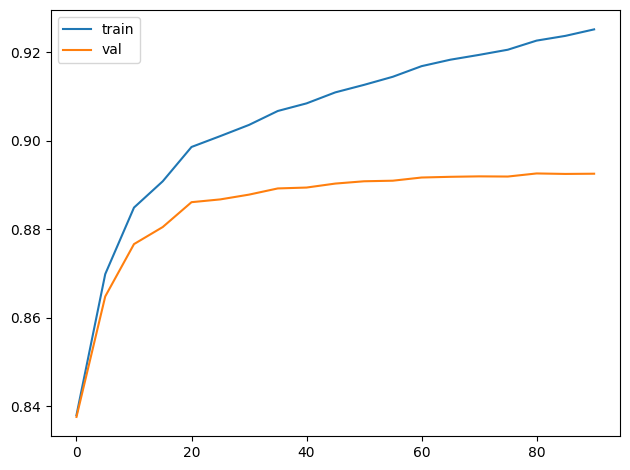

In [36]:
plt.plot(df_scores.num_iter, df_scores.train_auc, label="train")
plt.plot(df_scores.num_iter, df_scores.val_auc, label="val")

plt.legend()
plt.tight_layout()
plt.show()

In [37]:
y_pred = model.predict(dval,iteration_range=(0, model.best_iteration + 1))

auc = roc_auc_score(y_val, y_pred)

print("Validation AUC:", round(auc, 5))
print("Best iteration:", model.best_iteration)

Validation AUC: 0.89264
Best iteration: 80


In [38]:
scores = []

for eta in [0.01, 0.05, 0.1, 0.3, 1.0]:
    for max_depth in [3, 4, 5, 6, 8, 10]:

        params = xgb_params.copy()

        params["eta"] = eta
        params["max_depth"] = max_depth
        
        cv_results = xgb.cv(
            params=params, 
            dtrain=dtrain, 
            num_boost_round=500,
            nfold=5,
            stratified=True,
            metrics="auc",
            seed=42,
            early_stopping_rounds=10,
            verbose_eval=False
        ) 

        scores.append({
            "eta": eta,
            "max_depth": max_depth,
            "score": cv_results["test-auc-mean"].max(),
            "std": cv_results["test-auc-std"].iloc[
                cv_results["test-auc-mean"].argmax()
                ],
            "best_iteration": len(cv_results)
        })

df_scores = pd.DataFrame(scores)

df_scores.sort_values(by="score", ascending=False)

,eta,max_depth,score,std,best_iteration
16,0.10,8,0.894991,0.002642,206
11,0.05,10,0.894962,0.003076,292
17,0.10,10,0.894414,0.003101,129
10,0.05,8,0.894140,0.002892,377
15,0.10,6,0.892756,0.002891,336
5,0.01,10,0.891663,0.003115,500
22,0.30,8,0.891620,0.002953,83
9,0.05,6,0.891174,0.003222,500
14,0.10,5,0.891057,0.003507,417
21,0.30,6,0.891036,0.003149,124


In [39]:
scores_pivot = df_scores.pivot(
    index="max_depth",
    columns="eta",
    values="score"
)

scores_pivot

eta,0.01,0.05,0.10,0.30,1.00
max_depth,,,,,
3,0.852400,0.876174,0.883104,0.888744,0.880240
4,0.865850,0.884165,0.887906,0.890173,0.880557
5,0.874524,0.887868,0.891057,0.890603,0.879090
6,0.881549,0.891174,0.892756,0.891036,0.879728
8,0.888752,0.894140,0.894991,0.891620,0.878533
10,0.891663,0.894962,0.894414,0.890678,0.877367


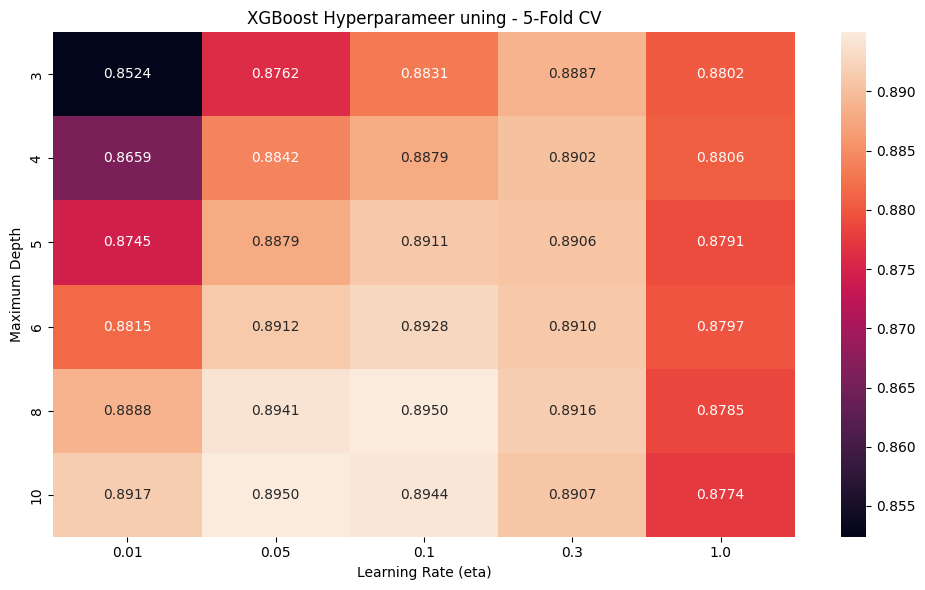

In [40]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    scores_pivot,
    annot=True,
    fmt=".4f"
)

plt.title("XGBoost Hyperparameer uning - 5-Fold CV")
plt.xlabel("Learning Rate (eta)")
plt.ylabel("Maximum Depth")

plt.tight_layout()
plt.show()

In [41]:
best_score = df_scores.sort_values(
    by="score",
    ascending=False
).iloc[0]

In [42]:
print("---Best Eta & Max Depth---")

print("Eta:", best_score["eta"])
print("Max Depth:", best_score["max_depth"])
print("Mean CV AUC:", round(best_score["score"], 4))
print("Standard Deviation:", round(best_score["std"], 4))
print("Best Iteration:", best_score["best_iteration"])

---Best Eta & Max Depth---
Eta: 0.1
Max Depth: 8.0
Mean CV AUC: 0.895
Standard Deviation: 0.0026
Best Iteration: 206.0


In [43]:
min_child_weights = [1, 3, 5, 7, 10]

scores_min_child = []

for min_child_weight in min_child_weights:

    params = xgb_params.copy()
    params["eta"] = 0.1
    params["max_depth"] = 8
    params["min_child_weight"] = min_child_weight

    cv_results = xgb.cv(
        params=params,
        dtrain=dtrain,
        num_boost_round=500,
        nfold=5,
        stratified=True,
        metrics="auc",
        seed=42,
        early_stopping_rounds=10,
        verbose_eval=False
    )

    best_idx = cv_results["test-auc-mean"].idxmax()

    scores_min_child.append({
        "min_child_weight": min_child_weight,
        "score": cv_results.loc[best_idx, "test-auc-mean"],
        "std": cv_results.loc[best_idx, "test-auc-std"],
        "best_iteration": int(best_idx) + 1
    })

df_min_child = pd.DataFrame(scores_min_child)

df_min_child.sort_values("score", ascending=False)

,min_child_weight,score,std,best_iteration
0,1,0.894991,0.002642,206
3,7,0.894603,0.002941,213
1,3,0.894575,0.003157,197
2,5,0.894556,0.003077,207
4,10,0.893777,0.002964,241


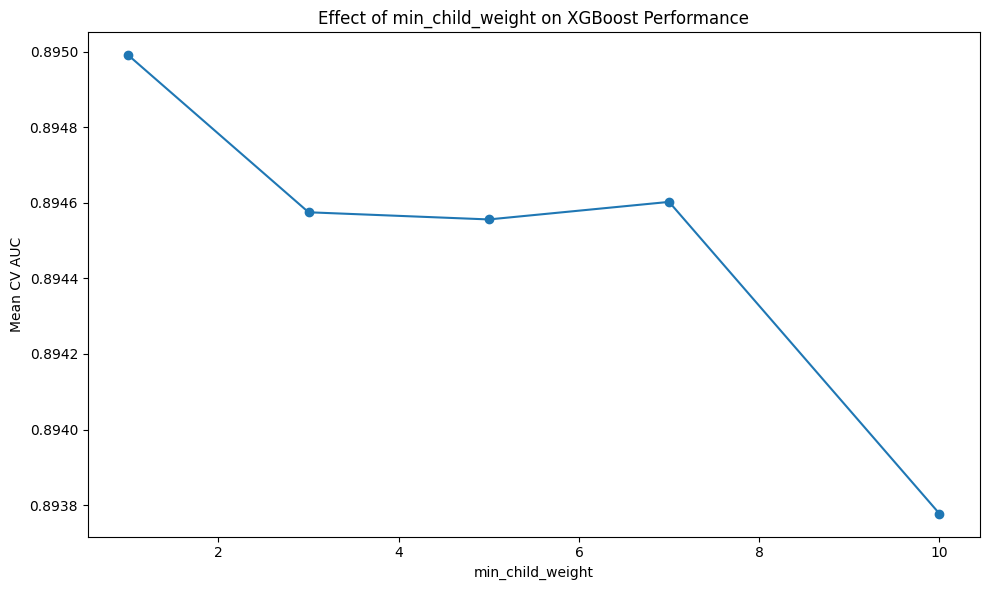

In [44]:
plt.figure(figsize=(10, 6))

plt.plot(
    df_min_child['min_child_weight'],
    df_min_child['score'],
    marker="o"
)

plt.xlabel("min_child_weight")
plt.ylabel("Mean CV AUC")
plt.title("Effect of min_child_weight on XGBoost Performance")

plt.tight_layout()
plt.show()

In [45]:
subsample_colsample_bytree_scores = []

for subsample in [0.8, 1.0]:
    for colsample_bytree in [0.8, 1.0]:

        params = xgb_params.copy()

        params["eta"] = 0.1
        params["max_depth"] = 8
        params["min_child_weight"] = 1
        params["subsample"] = subsample
        params["colsample_bytree"] = colsample_bytree

        cv_results = xgb.cv(
            params=params,
            dtrain=dtrain,
            num_boost_round=500,
            nfold=5,
            stratified=True,
            metrics="auc",
            seed=42,
            early_stopping_rounds=10,
            verbose_eval=False
        )

        best_idx = cv_results["test-auc-mean"].idxmax()

        subsample_colsample_bytree_scores.append({
            "subsample": subsample,
            "colsample_bytree": colsample_bytree,
            "score": cv_results.loc[best_idx, "test-auc-mean"],
            "std": cv_results.loc[best_idx, "test-auc-std"],
            "best_iteration": int(best_idx) + 1
        })

df_sampling = pd.DataFrame(subsample_colsample_bytree_scores)

df_sampling.sort_values(by="score", ascending=False)

,subsample,colsample_bytree,score,std,best_iteration
0,0.8,0.8,0.896118,0.003227,264
2,1.0,0.8,0.895290,0.002893,200
1,0.8,1.0,0.895272,0.002809,185
3,1.0,1.0,0.894991,0.002642,206


In [46]:
sampling_pivot = df_sampling.pivot(
    index="subsample",
    columns="colsample_bytree",
    values="score"
)

sampling_pivot

colsample_bytree,0.8,1.0
subsample,,
0.8,0.896118,0.895272
1.0,0.895290,0.894991


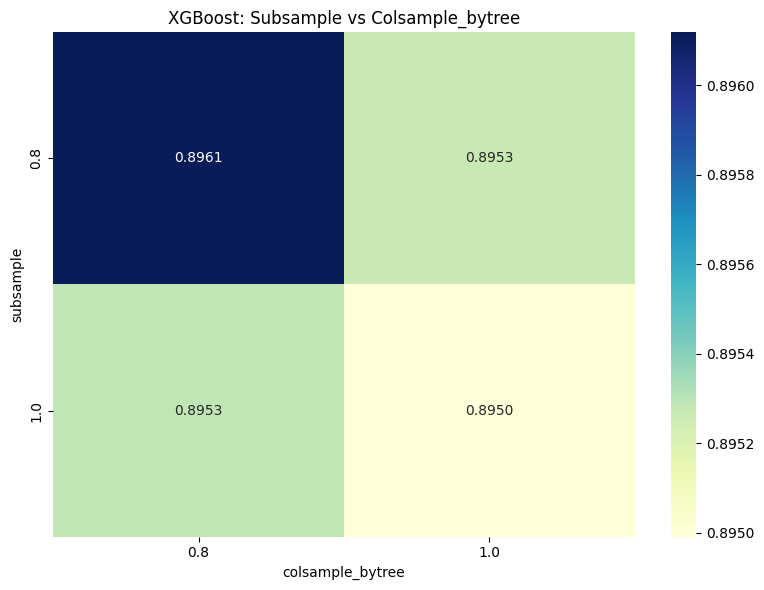

In [47]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    sampling_pivot,
    annot=True,
    fmt=".4f",
    cmap="YlGnBu"
)

plt.title("XGBoost: Subsample vs Colsample_bytree")
plt.xlabel("colsample_bytree")
plt.ylabel("subsample")

plt.tight_layout()
plt.show()

## 7. Train Selected Model and Evaluate on Validation Dataset

In [48]:
best_params = xgb_params.copy()

best_params["eta"] = 0.1
best_params["max_depth"] = 8
best_params["min_child_weight"] = 1
best_params["subsample"] = 0.8
best_params["colsample_bytree"] = 0.8

best_num_boost_round = 223

In [49]:
model_final = xgb.train(
    best_params,
    dtrain,
    num_boost_round=best_num_boost_round
)

In [50]:
y_val_pred = model_final.predict(dval)

In [51]:
val_auc = roc_auc_score(y_val, y_val_pred)

print("Validation AUC:", round(val_auc, 4))

Validation AUC: 0.8962


## 6. Model Comparison

Best validation AUC on each model type.

In [52]:
df_models = pd.DataFrame(model_scores,columns=["model", "parameters", "val_auc"])

# Best parameters of each model type
best_per_model = df_models.sort_values("val_auc", ascending=False).groupby("model").head(1)

# Add the tuned XGBoost model 
xgb_row  = pd.DataFrame([{
    "model": "XGBoost (tuned)",
    "parameters": "eta=0.1, max_depth=8, min_child_weight=1, subsample=0.8, colsample_bytree=0.8, 223 rounds",
    "val_auc": val_auc
}])

model_comparison = pd.concat([best_per_model, xgb_row]).sort_values('val_auc', ascending=False).reset_index(drop=True)
model_comparison['val_auc'] = model_comparison['val_auc'].round(4)
model_comparison

,model,parameters,val_auc
0,XGBoost (tuned),"eta=0.1, max_depth=8, min_child_weight=1, subs...",0.8962
1,Random Forest,"n_estimators=300, max_depth=25",0.8768
2,Decision Tree,"max_depth=10, min_samples_leaf=20",0.8728
3,Logistic Regression,C=10,0.8061


**Conclusion:** XGBoost has the highest validation AUC, so it is selected as the final model. It is retrained on training + validation data and evaluated once on the test set in the next sections.

## 7. Re-Train using Training + Validation Data

In [53]:
df_full_train.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type', 'deposit_type',
       'agent', 'days_in_waiting_list', 'customer_type', 'adr',
       'total_of_special_requests', 'has_company'],
      dtype='object')

In [54]:
X_full_train = dv.transform(df_full_train.drop(columns=['is_canceled']).to_dict(orient="records"))

y_full_train = df_full_train['is_canceled'].values

In [55]:
dfull_train = xgb.DMatrix(X_full_train, label=y_full_train, feature_names=features)

In [56]:
final_model = xgb.train(
    best_params,
    dfull_train,
    num_boost_round=best_num_boost_round
)

## 8. Evaluate on Test Dataset

In [57]:
y_test_pred = final_model.predict(dtest)

In [58]:
test_auc = roc_auc_score(y_test, y_test_pred)

print("Test AUC:", round(test_auc, 4))

Test AUC: 0.9033


## 9. Results Comparison

In [59]:
# Best 5-fold cross-validation AUC from the tuning (training data only)
cv_auc = df_sampling['score'].max()

results = pd.DataFrame({
    "Dataset": ["Cross-validation", "Validation", "Test"],
    "AUC": [auc, val_auc, test_auc]
})

results

,Dataset,AUC
0,Cross-validation,0.892642
1,Validation,0.896176
2,Test,0.903284
